In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/DataCoSupplyChainDataset.csv", encoding= "latin-1", sep=",")
columns_to_drop = [
    "Product Description",
    "Order Zipcode",
    "Customer Password"
]

df_clean = df.drop(columns=columns_to_drop).copy()

df_clean["order date (DateOrders)"] = pd.to_datetime(
    df_clean["order date (DateOrders)"],
    errors="coerce"
)

df_clean["shipping date (DateOrders)"] = pd.to_datetime(
    df_clean["shipping date (DateOrders)"],
    errors="coerce"
)

print(f"Dataset shape: {df_clean.shape}")


Dataset shape: (180519, 50)


## 1. Shipping Mode Distribution

This analysis examines the distribution of orders across shipping modes.
Understanding shipping-mode usage provides context for subsequent comparisons
of logistics performance.

Shipping Mode Counts


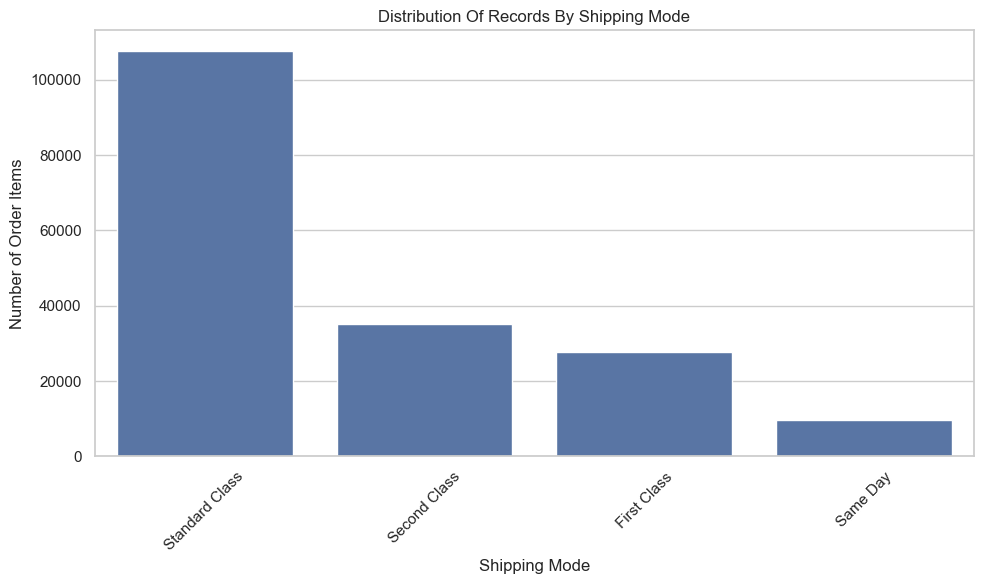

In [2]:
shipping_counts = (df_clean["Shipping Mode"].value_counts())
print("Shipping Mode Counts")

plt.figure(figsize=(10, 6))

sns.barplot(x=shipping_counts.index, y=shipping_counts.values)

plt.title("Distribution Of Records By Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Order Items")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [3]:
# examining late delivery risk by shipping mode

risk_by_mode = (
    df_clean.groupby("Shipping Mode")["Late_delivery_risk"].mean().mul(100).sort_values(ascending=False)
)

print(risk_by_mode.round(2))

Shipping Mode
First Class       95.32
Second Class      76.63
Same Day          45.74
Standard Class    38.07
Name: Late_delivery_risk, dtype: float64


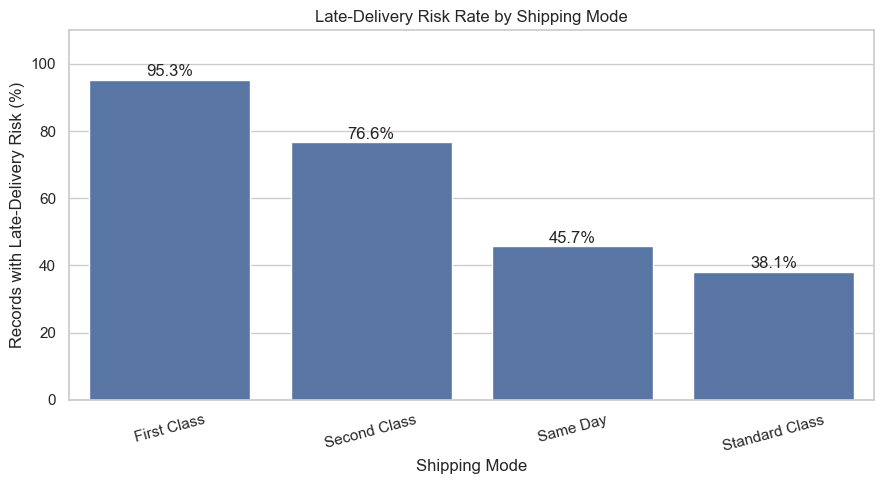

In [4]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=risk_by_mode.index,
    y=risk_by_mode.values
)

plt.title("Late-Delivery Risk Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Records with Late-Delivery Risk (%)")
plt.xticks(rotation=15)

for i, value in enumerate(risk_by_mode.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.ylim(0, 110)
plt.tight_layout()
plt.show()

In [5]:
shipping_time_summary = (
    df_clean.groupby("Shipping Mode")[
        [
            "Days for shipping (real)",
            "Days for shipment (scheduled)"
        ]
    ]
    .mean()
    .sort_values("Days for shipping (real)", ascending=False)
)

shipping_time_summary

,Days for shipping (real),Days for shipment (scheduled)
Shipping Mode,,
Standard Class,3.995907,4.0
Second Class,3.990828,2.0
First Class,2.000000,1.0
Same Day,0.478279,0.0


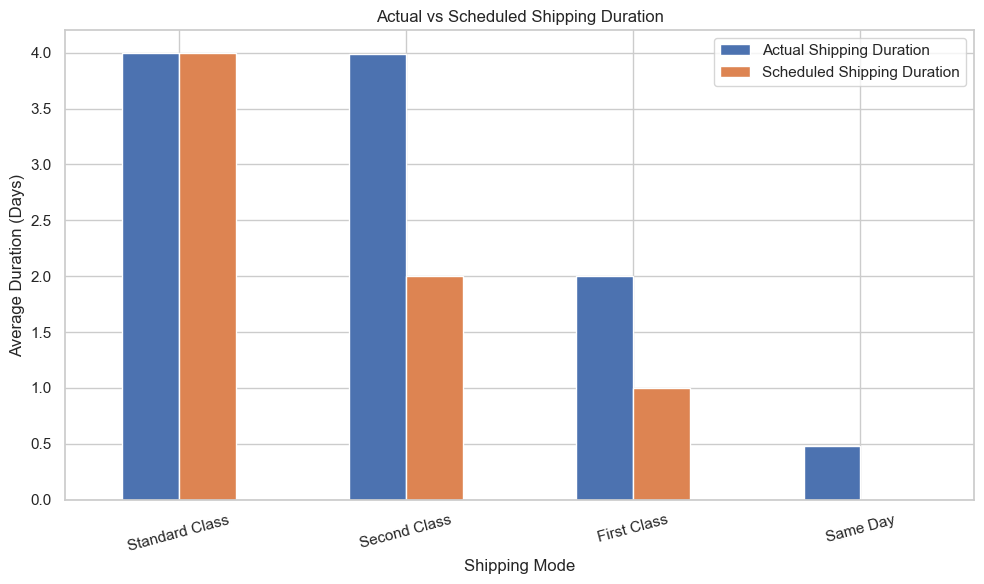

In [6]:
shipping_time_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Actual vs Scheduled Shipping Duration")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Duration (Days)")
plt.xticks(rotation=15)
plt.legend(
    ["Actual Shipping Duration", "Scheduled Shipping Duration"]
)
plt.tight_layout()
plt.show()

In [7]:
# Difference between actual and scheduled shipping duration
df_clean["shipping_delay_days"] = (
    df_clean["Days for shipping (real)"]
    - df_clean["Days for shipment (scheduled)"]
)

# Percentage of records where actual duration exceeded schedule
schedule_overrun_rate = (
    df_clean["shipping_delay_days"].gt(0)
    .groupby(df_clean["Shipping Mode"])
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(schedule_overrun_rate.round(2))

Shipping Mode
First Class       100.00
Second Class       79.73
Same Day           47.83
Standard Class     39.77
Name: shipping_delay_days, dtype: float64


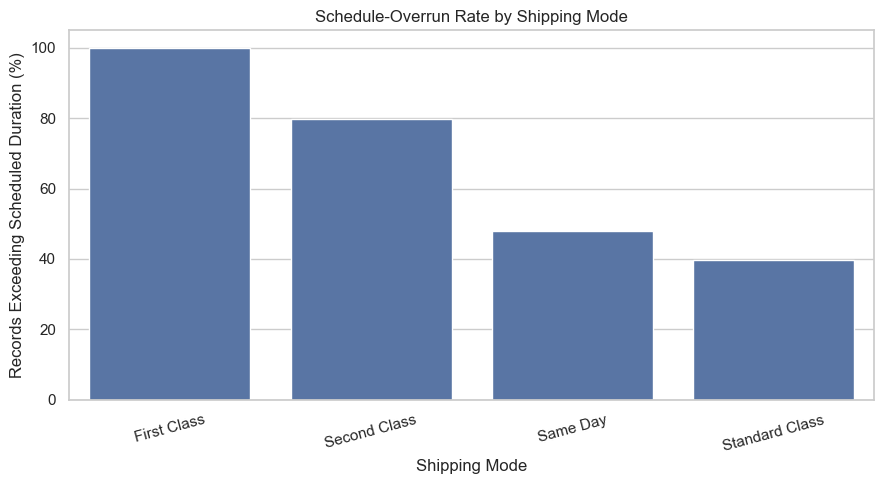

In [8]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=schedule_overrun_rate.index,
    y=schedule_overrun_rate.values
)

plt.title("Schedule-Overrun Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Records Exceeding Scheduled Duration (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Finding: Shipping Schedule Overruns

The exploratory analysis shows substantial differences in schedule-overrun rates across shipping modes. First Class has the highest observed rate, followed by Second Class, Same Day, and Standard Class. This pattern warrants further investigation into scheduled transit times and the relationship between shipping mode and delivery outcomes.

These findings are descriptive and do not establish causation. The analysis is conducted at the order-item level, and the relationship between schedule overruns and the dataset's `Late_delivery_risk` label requires further validation.


In [9]:
# analysing geographical differences
risk_by_region = (
    df_clean.groupby("Order Region")["Late_delivery_risk"]
    .agg(["mean", "count"])
)

risk_by_region["risk_rate_pct"] = risk_by_region["mean"] * 100

risk_by_region = risk_by_region.sort_values("risk_rate_pct", ascending=False)

risk_by_region.head(15).round(2)

,mean,count,risk_rate_pct
Order Region,,,
Central Africa,0.58,1677,57.96
South Asia,0.56,7731,56.27
East Africa,0.56,1852,55.94
Western Europe,0.56,27109,55.85
South of USA,0.56,4045,55.77
Eastern Europe,0.56,3920,55.66
East of USA,0.56,6915,55.66
Southeast Asia,0.56,9539,55.53
Central Asia,0.55,553,55.33


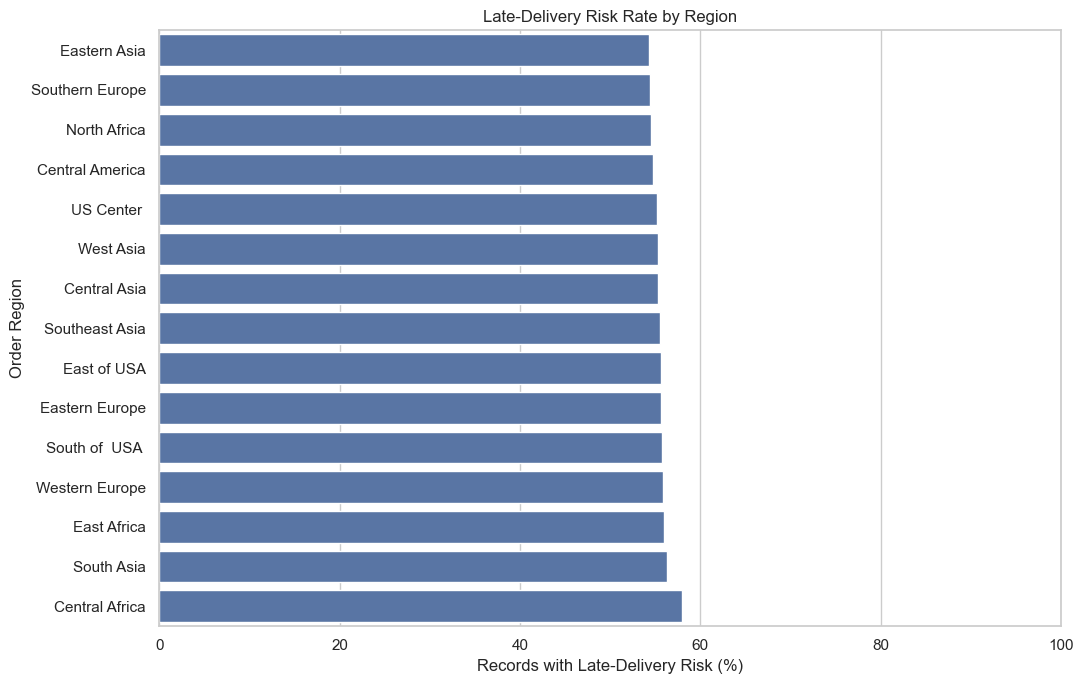

In [10]:
# creating regional chart
top_regions = risk_by_region.head(15).sort_values(
    "risk_rate_pct",
    ascending=True
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_regions,
    x="risk_rate_pct",
    y=top_regions.index
)

plt.title("Late-Delivery Risk Rate by Region")
plt.xlabel("Records with Late-Delivery Risk (%)")
plt.ylabel("Order Region")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### Finding: Regional Variation in Late-Delivery Risk

The 15 regions with the highest observed risk rates show relatively modest variation, ranging from approximately 54.3% to 58.0%. Central Africa records the highest rate in this subset, while Eastern Asia records the lowest. Record counts vary considerably between regions, so the percentages should be interpreted alongside the available sample sizes. Further statistical analysis is required before concluding that regional differences are meaningful or operationally important.


In [11]:
# investigating product categories
risk_by_category = (
    df_clean.groupby("Category Name")["Late_delivery_risk"]
    .agg(["mean", "count"])
)

risk_by_category["risk_rate_pct"] = (
    risk_by_category["mean"] * 100
)

risk_by_category = risk_by_category.sort_values(
    "risk_rate_pct",
    ascending=False
)

risk_by_category.round(2)

,mean,count,risk_rate_pct
Category Name,,,
Golf Bags & Carts,0.69,61,68.85
Lacrosse,0.60,343,60.06
Pet Supplies,0.59,492,58.94
Cameras,0.58,592,58.11
Strength Training,0.58,111,57.66
As Seen on TV!,0.57,68,57.35
Music,0.57,434,57.14
Accessories,0.57,1780,56.97
Fitness Accessories,0.57,309,56.96


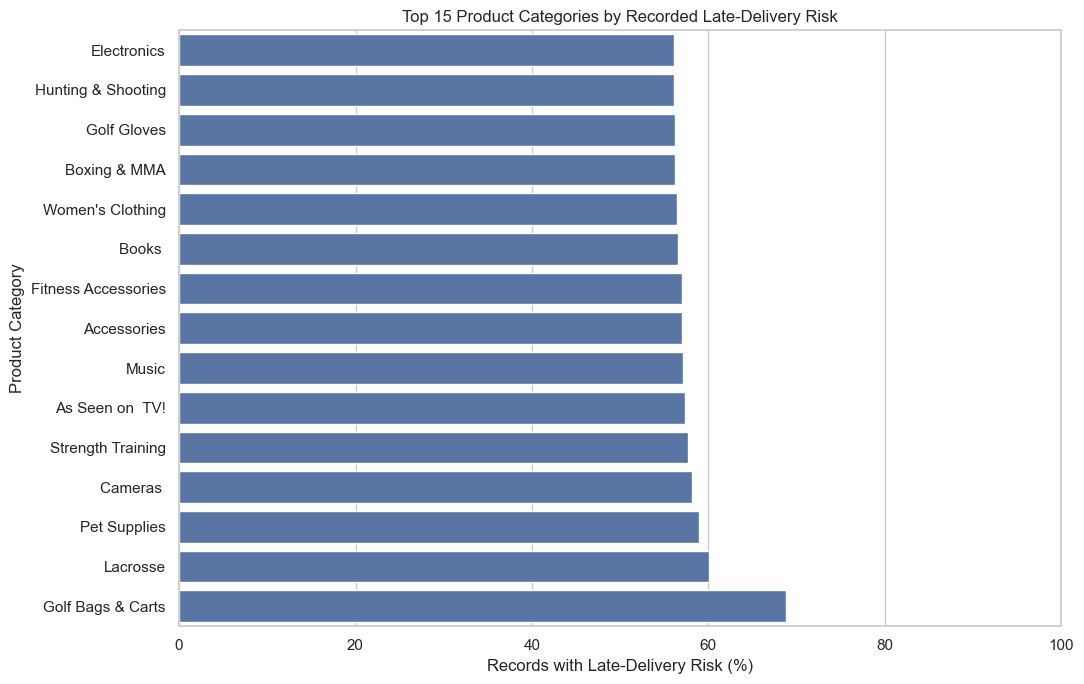

In [12]:
top_categories = risk_by_category.head(15).sort_values(
    "risk_rate_pct",
    ascending=True
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_categories,
    x="risk_rate_pct",
    y=top_categories.index
)

plt.title("Top 15 Product Categories by Recorded Late-Delivery Risk")
plt.xlabel("Records with Late-Delivery Risk (%)")
plt.ylabel("Product Category")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### Finding: Product Category and Late-Delivery Risk

Observed late-delivery risk varies across product categories. Golf Bags & Carts has the highest rate in the dataset, at approximately 68.9%, but this result is based on only 61 records. Several larger categories have rates close to 54–55%. These differences should be interpreted cautiously because sample sizes vary substantially, and further statistical analysis is needed to determine whether category-level differences are meaningful.


In [13]:
# analyse trends over time
print("Earliest order:", df_clean["order date (DateOrders)"].min())
print("Latest order:", df_clean["order date (DateOrders)"].max())

Earliest order: 2015-01-01 00:00:00
Latest order: 2018-01-31 23:38:00


In [14]:
# calculating monthly risk
df_clean["order_month"] = (
    df_clean["order date (DateOrders)"]
    .dt.to_period("M")
)

monthly_risk = (
    df_clean.groupby("order_month")["Late_delivery_risk"]
    .agg(["mean", "count"])
)

monthly_risk["risk_rate_pct"] = monthly_risk["mean"] * 100

monthly_risk.round(2)

,mean,count,risk_rate_pct
order_month,,,
2015-01,0.54,5322,54.11
2015-02,0.55,4729,54.85
2015-03,0.55,5362,54.76
2015-04,0.54,5126,53.84
2015-05,0.55,5357,55.09
2015-06,0.54,5134,54.11
2015-07,0.55,5299,55.46
2015-08,0.56,5273,55.68
2015-09,0.57,5140,56.69


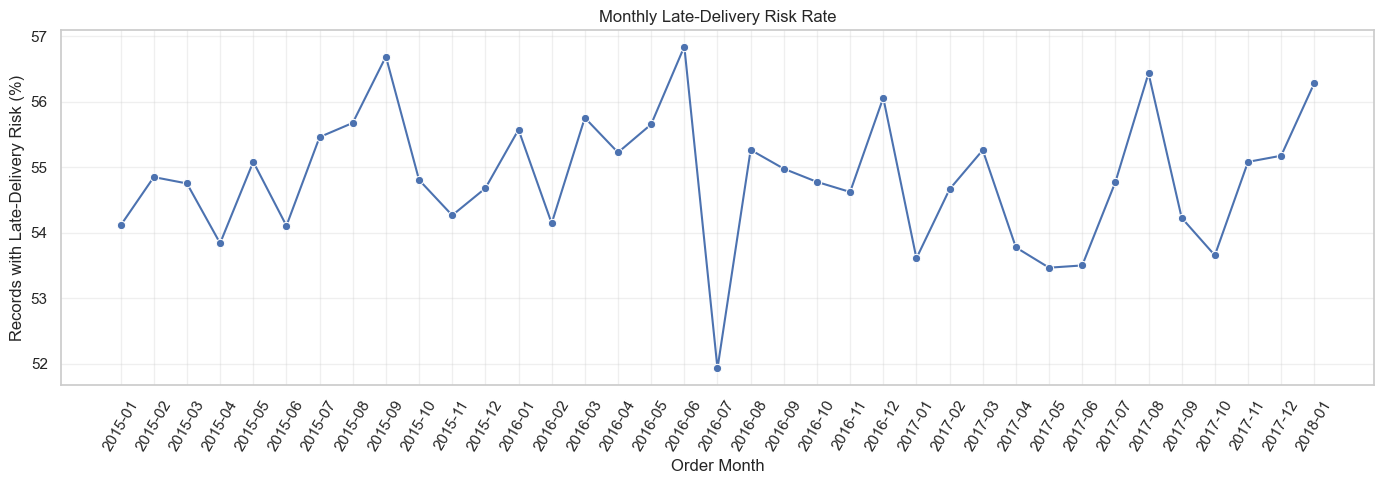

In [15]:
monthly_plot = monthly_risk.copy()

monthly_plot.index = monthly_plot.index.astype(str)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_plot,
    x=monthly_plot.index,
    y="risk_rate_pct",
    marker="o"
)

plt.title("Monthly Late-Delivery Risk Rate")
plt.xlabel("Order Month")
plt.ylabel("Records with Late-Delivery Risk (%)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
monthly_risk[["count"]].tail(12) # unusually low record counts

,count
order_month,
2017-02,4906
2017-03,5347
2017-04,5212
2017-05,5317
2017-06,4951
2017-07,5318
2017-08,5305
2017-09,5189
2017-10,2255


### Finding: Monthly Variation in Late-Delivery Risk

The monthly recorded late-delivery risk rate fluctuates over the observed period, with a high of approximately 56.85% in June 2016 and a low of 51.93% in July 2016. No consistent long-term trend can be established from these descriptive results alone. Record counts also decline in the final months of 2017, so data coverage should be investigated before drawing conclusions about temporal patterns.


In [17]:
df_clean["order date (DateOrders)"].agg(["min", "max"])

min   2015-01-01 00:00:00
max   2018-01-31 23:38:00
Name: order date (DateOrders), dtype: datetime64[us]

In [18]:
# daily records count near the end
daily_counts = (
    df_clean.assign(order_day=df_clean["order date (DateOrders)"].dt.date)
    .groupby("order_day")
    .size()
)
daily_counts.tail(15) # unusually low record counts

order_day
2018-01-17    68
2018-01-18    69
2018-01-19    68
2018-01-20    69
2018-01-21    68
2018-01-22    69
2018-01-23    68
2018-01-24    69
2018-01-25    68
2018-01-26    69
2018-01-27    68
2018-01-28    69
2018-01-29    68
2018-01-30    69
2018-01-31    68
dtype: int64

In [19]:
# comparing daily record counts across periods

df_clean["order_year_month"] = (
    df_clean["order date (DateOrders)"].dt.to_period("M")
)

daily_summary = (
    df_clean.assign(
        order_day=df_clean["order date (DateOrders)"].dt.date
    )
    .groupby("order_year_month")
    .agg(
        total_records=("Order Item Id", "count"),
        active_days=("order_day", "nunique"),
        avg_records_per_active_day=("Order Item Id", "count")
    )
)

daily_summary["avg_records_per_active_day"] = (
    daily_summary["total_records"] / daily_summary["active_days"]
)

daily_summary.tail(12).round(2)

,total_records,active_days,avg_records_per_active_day
order_year_month,,,
2017-02,4906,28,175.21
2017-03,5347,31,172.48
2017-04,5212,30,173.73
2017-05,5317,31,171.52
2017-06,4951,30,165.03
2017-07,5318,31,171.55
2017-08,5305,31,171.13
2017-09,5189,30,172.97
2017-10,2255,31,72.74


In [20]:
# checking whether the pattern is present across shipping modes

monthly_mode_counts = pd.crosstab(
    df_clean["order_month"],
    df_clean["Shipping Mode"]
)   

monthly_mode_counts.tail(12) # unusually low record counts

Shipping Mode,First Class,Same Day,Second Class,Standard Class
order_month,,,,
2017-02,717,303,977,2909
2017-03,864,295,999,3189
2017-04,749,243,1055,3165
2017-05,916,277,950,3174
2017-06,733,238,908,3072
2017-07,778,368,1083,3089
2017-08,832,275,1112,3086
2017-09,790,282,1027,3090
2017-10,352,110,418,1375


In [21]:
# calculating each mode's share of total records per month
monthly_mode_share = (
    monthly_mode_counts.div(monthly_mode_counts.sum(axis=1), axis=0)
    .mul(100)
)

monthly_mode_share.tail(12).round(2)

Shipping Mode,First Class,Same Day,Second Class,Standard Class
order_month,,,,
2017-02,14.61,6.18,19.91,59.29
2017-03,16.16,5.52,18.68,59.64
2017-04,14.37,4.66,20.24,60.73
2017-05,17.23,5.21,17.87,59.70
2017-06,14.81,4.81,18.34,62.05
2017-07,14.63,6.92,20.36,58.09
2017-08,15.68,5.18,20.96,58.17
2017-09,15.22,5.43,19.79,59.55
2017-10,15.61,4.88,18.54,60.98


### Data Coverage Check

Monthly record counts fall substantially from October 2017 onwards. However, the relative distribution of records across shipping modes remains broadly similar. This suggests that the decline is not explained solely by a major change in shipping-mode composition. The cause of the lower record volume remains uncertain and should be treated as a dataset limitation when interpreting temporal patterns.

In [22]:
# testing whether shipping mode and late delivery risk are statistically associated

from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df_clean["Shipping Mode"],
    df_clean["Late_delivery_risk"]
)

contingency_table

Late_delivery_risk,0,1
Shipping Mode,,
First Class,1301,26513
Same Day,5283,4454
Second Class,8229,26987
Standard Class,66729,41023


In [23]:
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 37716.04250472746
P-value: 0.0
Degrees of freedom: 3


### Statistical Finding: Shipping Mode and Late-Delivery Risk

The chi-square test indicates a statistically significant association between shipping mode and the dataset's Late_delivery_risk label The observed risk rates vary considerably across shipping modes, with First Class having a higher rate than Standard Class.
This result establishes an association, not causation. Cramér's V will be used to assess the strength of the relationship. The findings should also be interpreted in the context of the dataset's definitions and limitations.

In [24]:
# calculating Cramér's V to measure the strength of association

n = contingency_table.to_numpy().sum()
min_dim = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))
print("Cramér's V:", round(cramers_v, 4))

Cramér's V: 0.4571


### Finding: Strength of Association

Cramér's V was calculated as 0.4571, indicating a substantial association between shipping mode and the Late_delivery_risk label in this dataset. This complements the statistically significant chi-square test. The results suggest that recorded risk rates differ meaningfully across shipping modes, but they do not establish that shipping mode itself causes delays.

In [25]:
df_clean["shipping_delay_days"] = (
    df_clean["Days for shipping (real)"]
    - df_clean["Days for shipment (scheduled)"]
)

df_clean["shipping_delay_days"].describe()

count    180519.000000
mean          0.565807
std           1.490966
min          -2.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: shipping_delay_days, dtype: float64

In [27]:
#Finding the percentage of records that exceeded their scheduled duration

overrun_count = (
    df_clean["shipping_delay_days"] > 0
).sum()

overrun_rate = (
    df_clean["shipping_delay_days"] > 0
).mean() * 100

on_schedule_count = (
    df_clean["shipping_delay_days"] == 0
).sum()

early_count = (
    df_clean["shipping_delay_days"] < 0
).sum()

print("Records exceeding schedule:", overrun_count)
print(f"Schedule-overrun rate: {overrun_rate:.2f}%")
print("Records matching schedule:", on_schedule_count)
print("Records completed faster than schedule:", early_count)

Records exceeding schedule: 103400
Schedule-overrun rate: 57.28%
Records matching schedule: 33753
Records completed faster than schedule: 43366


In [28]:
delay_by_mode = (
    df_clean.groupby("Shipping Mode")["shipping_delay_days"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

delay_by_mode.round(2)

,mean,median,count
Shipping Mode,,,
Second Class,1.99,2.0,35216
First Class,1.00,1.0,27814
Same Day,0.48,0.0,9737
Standard Class,-0.00,0.0,107752


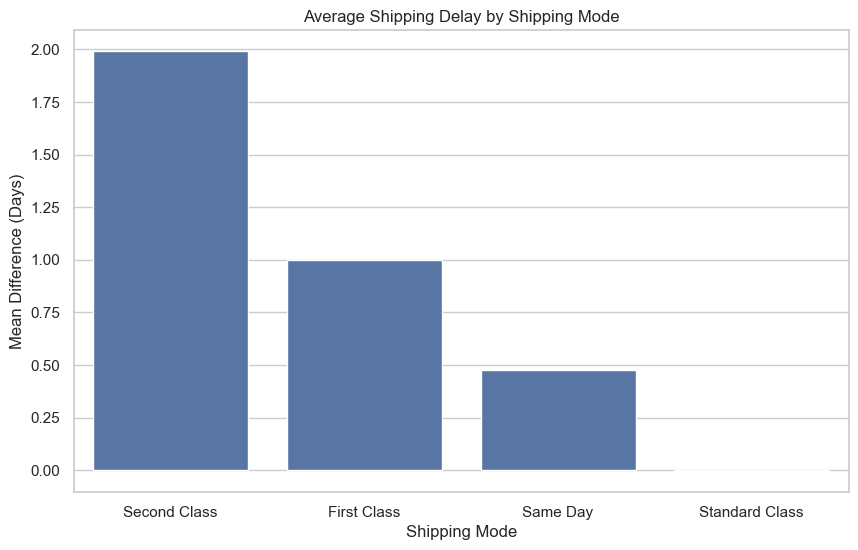

In [29]:
# visualizing the difference

plt.figure(figsize=(10, 6))

sns.barplot(
    data = delay_by_mode.reset_index(),
    x = "Shipping Mode",
    y = "mean"
)

plt.title("Average Shipping Delay by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Mean Difference (Days)")
plt.tight_layout
plt.show()

In [31]:
# Testing whether the differences are statistically significant
from scipy.stats import kruskal

shipping_groups = [
    group["shipping_delay_days"].to_numpy()
    for _, group in df_clean.groupby("Shipping Mode")
]

h_statistic, p_value = kruskal(*shipping_groups)

print("Kruskal-Wallis statistic:", h_statistic)
print("P-value:", p_value)

Kruskal-Wallis statistic: 41644.065446200024
P-value: 0.0


In [34]:
# identifying which pairs of shipping modes differ significantly using Dunn's test
import scikit_posthocs as sp

dunn_results = sp.posthoc_dunn(
    df_clean,
    val_col="shipping_delay_days",
    group_col="Shipping Mode",
    p_adjust="bonferroni"
)

dunn_results.round(6)

,First Class,Same Day,Second Class,Standard Class
First Class,1.0,0.0,0.0,0.0
Same Day,0.0,1.0,0.0,0.0
Second Class,0.0,0.0,1.0,0.0
Standard Class,0.0,0.0,0.0,1.0


### Statistical Analysis: Pairwise Shipping-Mode Comparisons

The Dunn post-hoc test with Bonferroni correction was performed following the Kruskal–Wallis test to examine pairwise differences in shipping-delay distributions across four shipping modes.

All six pairwise comparisons produced adjusted p-values below 0.05. Therefore, the results provide evidence of statistically significant differences in shipping-delay distributions between each pair of shipping modes.

Descriptive analysis showed that Second Class shipments had the largest average schedule overrun, followed by First Class and Same Day shipments. Standard Class shipments had an average schedule difference close to zero.

These findings indicate that shipping performance varies across shipping modes in the dataset. However, statistical significance alone does not establish practical importance or causation. Further analysis should consider effect sizes, shipment characteristics, and the operational context before making logistics recommendations.

Limitation: The shipping_delay_days variable measures the difference between actual and scheduled shipping durations in the dataset. It should not automatically be interpreted as the number of days a customer received a shipment late.